# 4.5 Important Theorems

**Goal:** understand what repeated-sampling results actually guarantee, when normal approximations are defensible, and how distribution-free bounds differ from exact probabilities.

**Prerequisites:** expectations and variance from 4.1; binomial, normal, exponential, and gamma distributions; basic sample means.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. If needed, install them in your chosen environment with `python3 -m pip install numpy scipy matplotlib`. Open in JupyterLab, Jupyter Notebook, or VS Code with a Python kernel. Use **Restart Kernel and Run All** to reproduce the saved text and figure outputs. Every notebook is self-contained; random examples use a local fixed seed. All data are synthetic or idealized model calculations, and no downloads are needed.

## Contents
1. Law of large numbers
2. Sampling distribution
3. Central limit theorem
4. Normal approximation
5. Chebyshev's inequality
6. ML uncertainty and assumptions
7. Practice and solutions

**Simulation caution:** a finite plot illustrates a theorem but cannot prove a limit statement. The results below state sufficient assumptions rather than covering every possible generalization. Independence, finite moments, and the target sampling process must be justified in an application.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, integrate, special

plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12,
                     "axes.labelsize": 10, "font.size": 10})
rng = np.random.default_rng(2026)

## 1. Law of Large Numbers (LLN)

For IID random variables $X_1,X_2,\ldots$ with $\mathbb E[|X_1|]<\infty$ and mean $\mu$, the sample mean $\bar X_n$ converges to $\mu$. The weak law expresses convergence **in probability**:
$$P(|\bar X_n-\mu|>\varepsilon)\to0\quad\text{for every }\varepsilon>0.$$
Under the same IID integrability condition the strong law gives convergence **almost surely**. These are distinct modes of convergence; the strong statement is stronger. Finite variance is a convenient sufficient condition for a simple Chebyshev proof, but it is not required for the standard IID integrable strong law.

For Bernoulli indicators, their sample mean is an observed event proportion, so the LLN explains convergence of relative frequency under IID sampling. It does not say a sample proportion equals p at a finite n, improves monotonically, or that past failures make a success due next.

**Worked example:** purchase indicators have fixed p=0.3 and are independently generated. Running averages fluctuate around the target and typically settle closer as n increases. If traffic composition or p changes, the fixed-distribution model may not describe the stream.

More observations do not cure selection bias. A survey repeatedly sampling only satisfied customers can converge to the wrong population quantity. Similarly, duplicating records increases row count without creating independent information.

n=10: running purchase proportion=0.2000
n=100: running purchase proportion=0.2500
n=1000: running purchase proportion=0.3260
n=20000: running purchase proportion=0.3007


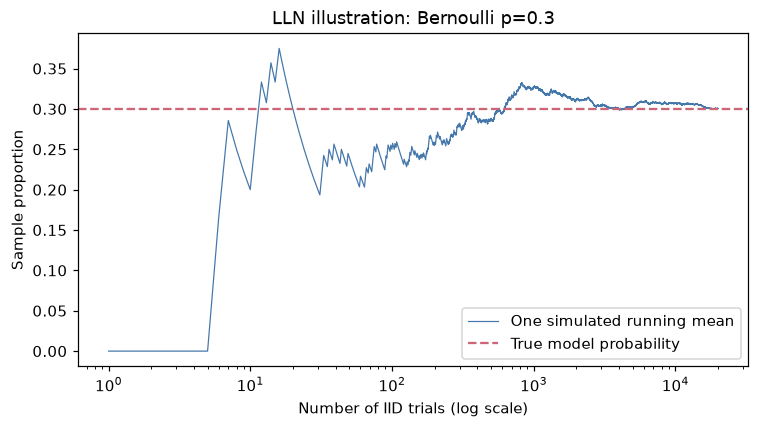

In [2]:
sample = rng.binomial(n=1, p=0.3, size=20000)
running_mean = np.cumsum(sample)/np.arange(1, len(sample)+1)
for n in [10, 100, 1000, 20000]:
    print(f"n={n}: running purchase proportion={running_mean[n-1]:.4f}")
fig, ax = plt.subplots()
ax.plot(np.arange(1, len(sample)+1), running_mean, color="#4477AA", linewidth=0.8, label="One simulated running mean")
ax.axhline(0.3, color="#CC6677", linestyle="--", label="True model probability")
ax.set(xscale="log", title="LLN illustration: Bernoulli p=0.3", xlabel="Number of IID trials (log scale)", ylabel="Sample proportion")
ax.legend()
fig.tight_layout()
plt.show()

## 2. Sampling Distribution

A sampling distribution is the probability distribution of a **statistic over hypothetical repetitions of the sampling procedure**. It differs from the distribution of individual observations and from a histogram of one dataset.

For IID observations with mean $\mu$ and finite variance $\sigma^2$:
$$\mathbb E[\bar X_n]=\mu,\qquad\operatorname{Var}(\bar X_n)=\frac{\sigma^2}{n},\qquad\operatorname{SE}(\bar X_n)=\frac\sigma{\sqrt n}.$$
These moment identities are exact; they do not require normally distributed X. A normal **shape** for the mean is a separate exact or approximate statement. If $\sigma$ is unknown, $s/\sqrt n$ estimates the standard error under the IID model, but replacing $\sigma$ with s does not automatically give an exact normal statistic.

**Worked example:** an exponential rate-1 observation has mean 1 and SD 1. A mean of n=25 independent observations has expectation 1 and standard error 0.2. Its distribution is exactly Gamma(shape=25,scale=1/25), not exactly normal. A plot of many simulated means approximates that sampling distribution.

Sampling without replacement from a finite population needs an appropriate finite-population correction; repeated time-series or cluster observations need dependence-aware variance estimates. Merely inserting the row count into $\sigma/\sqrt n$ can understate uncertainty.

Average simulated sample mean: 0.9957364656359466 target: 1
SD of simulated means: 0.19791423591461307 exact SE: 0.2


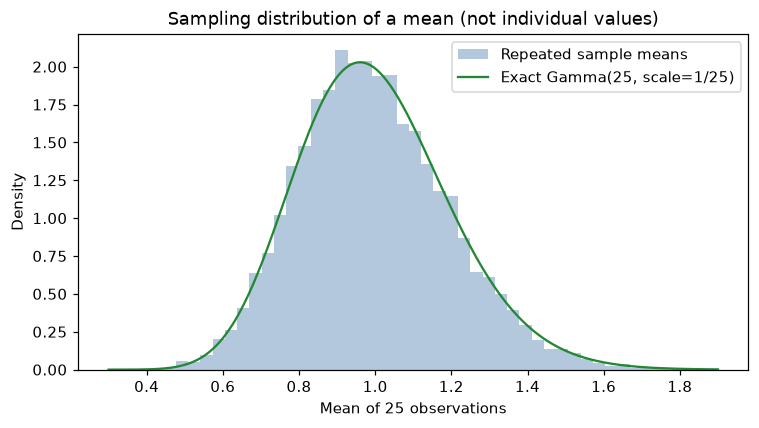

In [3]:
repetitions, n = 10000, 25
sample_means = rng.exponential(scale=1, size=(repetitions, n)).mean(axis=1)
exact_mean_distribution = stats.gamma(a=n, scale=1/n)
print("Average simulated sample mean:", sample_means.mean(), "target:", 1)
print("SD of simulated means:", sample_means.std(ddof=1), "exact SE:", 1/np.sqrt(n))
assert np.isclose(exact_mean_distribution.mean(), 1)
assert np.isclose(exact_mean_distribution.std(), 0.2)
grid = np.linspace(0.3, 1.9, 401)
fig, ax = plt.subplots()
ax.hist(sample_means, bins=45, density=True, alpha=0.4, color="#4477AA", label="Repeated sample means")
ax.plot(grid, exact_mean_distribution.pdf(grid), color="#228833", label="Exact Gamma(25, scale=1/25)")
ax.set(title="Sampling distribution of a mean (not individual values)", xlabel="Mean of 25 observations", ylabel="Density")
ax.legend()
fig.tight_layout()
plt.show()

## 3. Central Limit Theorem (CLT)

For IID variables with mean $\mu$ and **finite, nonzero variance** $\sigma^2$, the classical CLT states
$$Z_n=\frac{\sqrt n(\bar X_n-\mu)}\sigma\ \xrightarrow{d}\ \mathcal N(0,1).$$
The arrow means convergence in distribution. For large enough n in a particular problem, the sample mean is therefore approximately $\mathcal N(\mu,\sigma^2/n)$. If the original variables are normal, their independent sample mean is exactly normal for every positive n; the CLT is not needed for that exact result.

**LLN versus CLT:** LLN says the sample mean concentrates near the population mean. CLT describes the scaled distribution of the remaining fluctuations. It does not make the raw data normal, and it does not imply that the unscaled sample mean converges to a standard normal; unscaled means concentrate at $\mu$.

**Worked example:** rate-1 exponential data are right-skewed. As n grows, standardized means become more nearly normal. The exact standardized-mean skewness is $2/\sqrt n$, so the convergence of shape can be quantified here.

There is no universal “n≥30” guarantee. Strong skewness, rare events, heavy tails, dependence, and the probability region of interest affect approximation quality. A central approximation can be reasonable while extreme-tail probabilities remain poor.

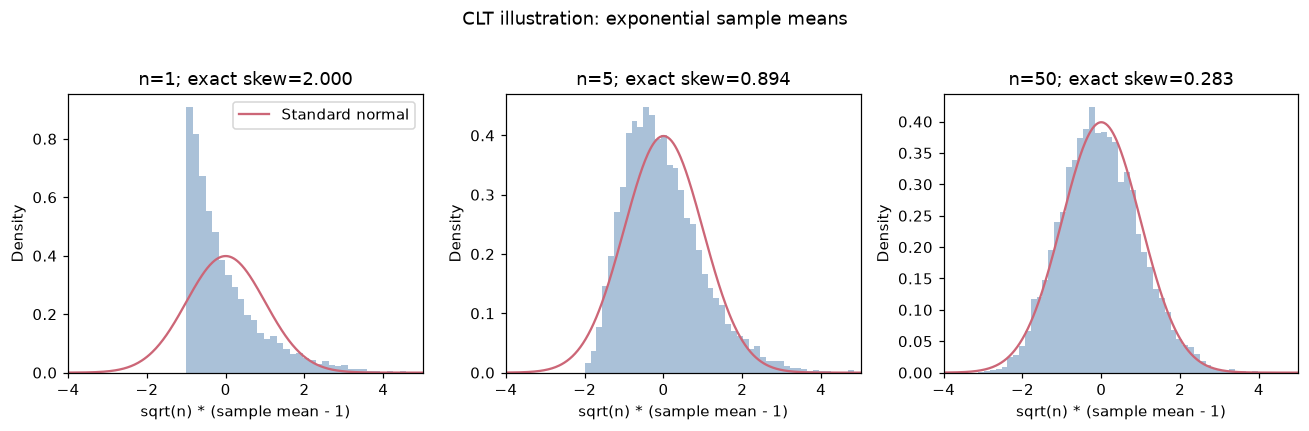

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
z_grid = np.linspace(-4, 5, 401)
for ax, n in zip(axes, [1, 5, 50]):
    means = rng.exponential(scale=1, size=(10000, n)).mean(axis=1)
    standardized_means = np.sqrt(n)*(means-1)
    ax.hist(standardized_means, bins=55, density=True, alpha=0.45, color="#4477AA")
    ax.plot(z_grid, stats.norm.pdf(z_grid), color="#CC6677", label="Standard normal")
    ax.set(title=f"n={n}; exact skew={2/np.sqrt(n):.3f}", xlabel="sqrt(n) * (sample mean - 1)", ylabel="Density", xlim=(-4, 5))
axes[0].legend()
fig.suptitle("CLT illustration: exponential sample means", y=1.02)
fig.tight_layout()
plt.show()

### A counterexample when assumptions fail

A standard Cauchy variable is symmetric but has no finite mean or variance. The average of IID standard Cauchy variables is still standard Cauchy for every n. It does not concentrate like an integrable sample mean, and the classical finite-variance CLT above does not apply.

The demonstration compares IQRs of averages rather than reporting an unstable “true Cauchy mean.” The theoretical IQR stays 2, unlike the shrinking exponential-mean IQR. Finite simulations fluctuate and can contain very large values; that is not a code error.

Dependence is another failure mode: if every observation is the same random quantity Z, then $\bar X_n=Z$ for all n. Its variance does not shrink with nominal row count. Specialized dependent-data limit theorems exist but need their own assumptions.

In [5]:
for n in [1, 10, 50]:
    cauchy_means = stats.cauchy.rvs(size=(6000, n), random_state=rng).mean(axis=1)
    empirical_iqr = np.quantile(cauchy_means, 0.75)-np.quantile(cauchy_means, 0.25)
    print(f"Cauchy averages n={n}: empirical IQR={empirical_iqr:.3f}; theoretical IQR=2")
print("No finite Cauchy population mean or variance is being estimated here.")

Cauchy averages n=1: empirical IQR=2.058; theoretical IQR=2
Cauchy averages n=10: empirical IQR=1.999; theoretical IQR=2
Cauchy averages n=50: empirical IQR=1.973; theoretical IQR=2
No finite Cauchy population mean or variance is being estimated here.


## 4. Normal Approximation

For $X\sim\operatorname{Binomial}(n,p)$ with $0<p<1$, a common approximation is $Y\sim\mathcal N(np,np(1-p))$. It is often more useful when both np and n(1-p) are reasonably large; requiring each to be at least 10 is a **heuristic**, not a theorem guaranteeing a specified error.

Because X is discrete and Y continuous, use a **continuity correction** when approximating integer ranges:
$$P(a\le X\le b)\approx P(a-0.5\le Y\le b+0.5),$$
$$P(X\le k)\approx P(Y\le k+0.5),\qquad P(X\ge k)\approx P(Y\ge k-0.5).$$
For an exact integer point $P(X=k)$, approximate the continuous interval [k-0.5,k+0.5], not the zero-probability event Y=k.

**Worked example:** for Binomial(100,0.4), mean is 40 and variance 24. Approximate $P(35\le X\le45)$ using bounds 34.5 and 45.5. Compare it to the exact binomial CDF difference rather than trusting a sample-size slogan.

Poisson(λ) counts also approach normal shape as λ grows, with mean and variance λ; continuity correction remains relevant. Rare binomial successes can be better modeled by a Poisson approximation when n is large, p small, and np moderate. Exact numerical CDFs are preferable when available and the model is simple.

In [6]:
n, p = 100, 0.4
mu, sd = n*p, np.sqrt(n*p*(1-p))
exact = stats.binom.cdf(45, n, p)-stats.binom.cdf(34, n, p)
corrected = stats.norm.cdf(45.5, mu, sd)-stats.norm.cdf(34.5, mu, sd)
uncorrected = stats.norm.cdf(45, mu, sd)-stats.norm.cdf(35, mu, sd)
print("Exact P(35 <= X <= 45):", exact)
print("Continuity-corrected normal:", corrected, "absolute error:", abs(corrected-exact))
print("Uncorrected normal:", uncorrected, "absolute error:", abs(uncorrected-exact))
# Large n alone is insufficient when expected success count is tiny.
rare_exact = stats.binom.cdf(0, n=100, p=0.001)
rare_normal = stats.norm.cdf(0.5, loc=0.1, scale=np.sqrt(0.1*0.999))
print("Rare-success example P(X=0): exact=", rare_exact, "normal CDF approximation=", rare_normal)
assert abs(corrected-exact) < 0.01  # Check this specific well-behaved worked example.

Exact P(35 <= X <= 45): 0.7385730184692495
Continuity-corrected normal: 0.7384277639860506 absolute error: 0.00014525448319890888
Uncorrected normal: 0.6925658340726046 absolute error: 0.04600718439664486
Rare-success example P(X=0): exact= 0.904792147113709 normal CDF approximation= 0.8971618059736504


## 5. Chebyshev's Inequality

For any random variable with finite mean $\mu$ and finite positive variance $\sigma^2$, and any $k>0$,
$$P(|X-\mu|\ge k\sigma)\le\frac1{k^2}.$$
The bound does not require normality, symmetry, or a particular distribution family. For k≤1 it can be uninformative; probabilities are also bounded by 1. An equivalent statement is $P(|X-\mu|<k\sigma)\ge1-1/k^2$. Endpoint strictness follows from taking the complement of the displayed event; in continuous models endpoints have probability zero.

At k=2, no more than 25% can be at least 2 SDs away. Under a normal model the exact probability is about 4.55%, showing how conservative a distribution-free bound may be. At k=3, Chebyshev guarantees at least 8/9 within 3 SDs (using the complementary convention), not the normal-model value of about 99.73%.

For an IID sample mean with finite variance,
$$P(|\bar X_n-\mu|\ge\varepsilon)\le\frac{\sigma^2}{n\varepsilon^2}.$$
This proves the weak LLN under the stronger finite-variance condition. For Bernoulli observations, $p(1-p)\le1/4$, so the bound is at most $1/(4n\varepsilon^2)$ regardless of p. These are model-based upper bounds, not exact confidence statements obtained by replacing an unknown population variance with any arbitrary estimate.

**Worked example:** to guarantee this bound is at most 0.05 for absolute sample-proportion error at least 0.05, choose $n\ge1/[4(0.05)(0.05^2)]=2000$. This is a conservative sufficient size under IID Bernoulli sampling, not a universal sample-size recommendation for every dataset.

In [7]:
for k in [2, 3]:
    bound = min(1.0, 1/k**2)
    actual_normal = 2*stats.norm.sf(k)
    print(f"k={k}: Chebyshev upper bound={bound:.6f}, normal actual tail={actual_normal:.6f}")
epsilon, error_probability = 0.05, 0.05
required_n = math.ceil(1/(4*error_probability*epsilon**2))
print("Conservative IID Bernoulli sufficient n:", required_n)
# Compare finite-n exact binomial error to the bound using strict complement carefully.
n, p, tolerance = 100, 0.3, 0.1
k_values = np.arange(n+1)
outside = np.abs(k_values-n*p) >= n*tolerance  # integer count distances here avoid proportion-rounding ambiguity
actual = stats.binom.pmf(k_values[outside], n, p).sum()
bound = min(1.0, p*(1-p)/(n*tolerance**2))
print("Exact probability |sample proportion - p| >= 0.1:", actual)
print("Chebyshev upper bound for this p:", bound)
assert actual <= bound+1e-12

k=2: Chebyshev upper bound=0.250000, normal actual tail=0.045500
k=3: Chebyshev upper bound=0.111111, normal actual tail=0.002700
Conservative IID Bernoulli sufficient n: 2000
Exact probability |sample proportion - p| >= 0.1: 0.03745142924579416
Chebyshev upper bound for this p: 0.20999999999999994


## 6. AI/ML uncertainty and evaluation

A held-out accuracy is a sample proportion. Under an IID fixed-model evaluation with a common success probability, its repeated-sample variance is p(1-p)/n. Reusing training cases, tuning repeatedly on the test set, clustered users, changing labels, or distribution shifts can violate that simple uncertainty calculation.

Monte Carlo estimates of an expected predictive quantity also use LLN reasoning; their finite-sample variability depends on the sampling distribution and dependence of generated draws. More Monte Carlo draws reduce computational integration noise under valid conditions, but do not remove uncertainty about model parameters, calibration errors, or misspecification.

Do not confuse an approximate normal sampling distribution of a statistic with normal features or normal outcomes. Likewise, a predictive distribution for one future observation and a sampling distribution of a fitted estimator describe different random quantities.

| Result/concept | Main message | Essential caution |
|---|---|---|
| LLN | Sample averages converge under assumptions | Not monotone; no cure for bias |
| Sampling distribution | Statistics vary across repeated samples | Unit and design determine variance |
| CLT | Standardized means approach a normal under conditions | Finite nonzero variance; no universal n cutoff |
| Normal approximation | Replace a discrete model with a continuous approximation | Check regime, endpoints, tails, and correction |
| Chebyshev | A finite-variance tail bound without shape assumptions | Can be loose; bound is not exact probability |

## Practice

1. Distinguish the LLN from the CLT in one or two sentences.
2. IID observations have SD 12. What is the standard error of their mean for n=36? How many observations reduce it to 1?
3. Does n=100 guarantee a good normal approximation for Binomial(100,0.001)? Why?
4. Under Binomial(80,0.5), write continuity-corrected normal bounds for $P(30\le X\le45)$.
5. What Chebyshev upper bound applies to deviations at least 4 SDs from the mean?
6. For IID observations with variance 9, use Chebyshev to bound $P(|\bar X_{100}-\mu|\ge1)$.
7. Why does the usual finite-variance CLT not apply to a standard Cauchy sample mean?
8. Does averaging 100 exact duplicate copies of the same random observation reduce its variance by a factor of 100?
9. For a rate-1 exponential population, give the exact distribution of the mean of 10 IID observations and its variance.
10. Is a normal-model interval for individual observations the same as a sampling interval for a mean?

## Solutions

1. LLN concerns concentration of averages near their mean; CLT concerns the approximate normal shape of appropriately scaled fluctuations around that mean.
2. $12/\sqrt{36}=2$. To get SE 1, solve $12/\sqrt n=1$, giving n=144, under the same IID variance assumptions.
3. No. Expected successes are only 0.1, so the count remains concentrated near zero and strongly nonnormal. Large n without the p regime is insufficient.
4. Use Y with mean 40 and SD $\sqrt{20}$, and compute $P(29.5\le Y\le45.5)$.
5. $1/4^2=1/16=0.0625$, or 6.25%, assuming a finite positive variance.
6. $9/(100\times1^2)=0.09$.
7. It has no finite mean or variance. Its independent sample mean remains standard Cauchy rather than concentrating normally.
8. No. All copies are perfectly dependent and their average equals the original observation.
9. Gamma(shape=10,scale=0.1); mean 1 and variance 0.1.
10. No. One describes variation of outcomes, the other variation of an estimator across samples; the latter often shrinks with sample size under suitable assumptions.

## Module 4 recap

You should now be able to choose a distribution from its support and data-generating assumptions, compute probabilities using PMFs/PDFs/CDFs, distinguish location/scale/shape/rate, and interpret moments and quantiles. You should also be able to separate parameter uncertainty, outcome variation, sampling error, and Monte Carlo error when reading ML model outputs.

The module connects these ideas to logistic regression's Bernoulli likelihood, Naive Bayes conditional distributions, generative sampling, beta–Bernoulli inference, a checkable variational approximation, and uncertainty estimation. These applications depend on a suitable model and independent evaluation, not on a named family alone.

**Readiness check:** state the assumptions before quoting a theorem or approximation, and compare an approximation with an exact calculation whenever it is available.

**Next:** Module 5 — Sampling and Inferential Statistics in the existing [main syllabus](../README.md).